# Qwen-27B Outcome-Flip Expanded-Support Confirmation (v2)

This A100 notebook closes the remaining route-conditionality evidence gap without lowering the original eight-bundle decision threshold.

[实验设置与运行说明](../../../docs/experiment_notes/10_exploratory_composition_and_gating/e9ad0d6405480e43.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_TRACKED_CELLS = 18
_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(total=total, initial=initial, desc=label, unit='cell',
               dynamic_ncols=True, leave=True)
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()
    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )
    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set(); worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close(); _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1); _SETUP_PROGRESS.close()
print(f'Cell progress helper ready: {_TRACKED_CELLS} tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 18 tracked cells.


In [2]:
%%cell_progress 1/18 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/18 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/18 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/18 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/18 Verify GPU and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify GPU and Hugging Face access:  11%|#1        | 2/18 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/18 Lock the outcome-flip confirmation protocol
cell_stage('Freezing model, route, cohort rules, estimands, and decisions')
import hashlib
import json
from datetime import datetime, timezone

MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
EXPECTED_LAYER_COUNT = 64
UPSTREAM_LAYER = 48
UPSTREAM_SCOPE = 'options_tokens'
CANDIDATE_LAYERS = (49, 57)
SITE_BATCH_SIZE = 4
IMAGE_TOKEN_ID_OVERRIDE = None

SEED = 20261130
FACTOR = 'weight'
SOURCE_KEYS = ('s1', 's2', 's3')
TARGET_KEYS = ('t1', 't2', 't3')
ORIENTATIONS = ('original', 'mirror')
MAPPING_VARIANTS = ('forward', 'reverse')
CONDITIONS = (
    'clean', 'natural_hybrid', 'shared', 'random_shared',
    'reverse_shared', 'self_replay', 'joint_restore', 'joint_random',
)
REQUESTED_BUNDLES = 48
MINIMUM_BUNDLES = 24
MINIMUM_FAMILIES = 16
MINIMUM_DISCORDANT_BUNDLES = 8
MAX_BUNDLES_PER_FAMILY = 2
EXPANSION_FAMILIES_PER_GROUP = 24
EXPANSION_POOL_PER_GROUP = 300
MAX_GENERATION_ATTEMPTS = 400000
MIN_COUNTERFACTUAL_NORM = 0.05
MIN_WITHIN_MARGIN_RANGE = 0.25
BOOTSTRAP_REPLICATES = 10000
ALPHA = 0.05
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.15
NORM_RELATIVE_TOLERANCE = 1e-3
PRIMARY_METRIC = 'route_specificity'
CONFIRMATORY_METRIC = 'route_attenuation'
BOUNDARY_METRIC = 'shared_over_random'

PRIOR_ROUTE_ROOT = PROJECT_ROOT / 'results' / 'qwen27b_factor_path_token_component_v2'
PRIOR_RUN_PATH = PRIOR_ROUTE_ROOT / 'RUN_COMPLETE.json'
PRIOR_SELECTION_PATH = PRIOR_ROUTE_ROOT / 'analysis' / 'frozen_sites.json'
PRIOR_FACTORIAL_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_weight_route_mapping_side_factorial_v1'
)
PRIOR_FACTORIAL_RUN = PRIOR_FACTORIAL_ROOT / 'RUN_COMPLETE.json'
PRIOR_CANDIDATE_PATH = PRIOR_FACTORIAL_ROOT / 'candidate_manifest.jsonl'
PRIOR_CONFIRMATION_PATH = PRIOR_FACTORIAL_ROOT / 'confirmation_manifest.jsonl'
PARENT_COMPOSITION_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_final_crosscontext_factor_composition_v1'
)
PARENT_CANDIDATE_PATH = PARENT_COMPOSITION_ROOT / 'candidate_manifest.jsonl'
PARENT_CONFIRMATION_PATH = PARENT_COMPOSITION_ROOT / 'confirmation_manifest.jsonl'
PRIOR_OUTCOMEFLIP_V1_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_outcomeflip_withincontext_route_confirmation_v2_expanded'
)
PRIOR_OUTCOMEFLIP_V1_CANDIDATE_PATH = PRIOR_OUTCOMEFLIP_V1_ROOT / 'candidate_manifest.jsonl'
PRIOR_OUTCOMEFLIP_V1_CONFIRMATION_PATH = PRIOR_OUTCOMEFLIP_V1_ROOT / 'confirmation_manifest.jsonl'

SHARED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'qwen27b_outcomeflip_withincontext_route_confirmation_v2_expanded'
)
CANDIDATE_MANIFEST_PATH = SHARED_ROOT / 'candidate_manifest.jsonl'
CANDIDATE_LOCK_PATH = SHARED_ROOT / 'candidate_manifest_lock.json'
SCREEN_DIR = SHARED_ROOT / 'endpoint_screen'
BUNDLE_MANIFEST_PATH = SHARED_ROOT / 'confirmation_bundle_manifest.jsonl'
CONFIRMATION_MANIFEST_PATH = SHARED_ROOT / 'confirmation_manifest.jsonl'
CONFIRMATION_LOCK_PATH = SHARED_ROOT / 'confirmation_manifest_lock.json'
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
SHARD_DIR = SHARED_ROOT / 'family_shards'
ANALYSIS_DIR = SHARED_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
for path in (SHARED_ROOT, SCREEN_DIR, SHARD_DIR, ANALYSIS_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

def json_default(value):
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, Path): return str(value)
    raise TypeError(type(value).__name__)

def write_json_atomic(path, value):
    path = Path(path); temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False,
                   default=json_default) + '\n', encoding='utf-8'
    )
    temporary.replace(path)

def write_jsonl_atomic(path, rows):
    path = Path(path); temporary = path.with_suffix(path.suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(
                row, sort_keys=True, default=json_default
            ) + '\n')
    temporary.replace(path)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value!r}'.encode('utf-8')).hexdigest()

for required in (
    PRIOR_RUN_PATH, PRIOR_SELECTION_PATH, PRIOR_FACTORIAL_RUN,
    PRIOR_CANDIDATE_PATH, PRIOR_CONFIRMATION_PATH,
    PARENT_CANDIDATE_PATH, PARENT_CONFIRMATION_PATH,
):
    assert required.is_file(), f'Missing prerequisite: {required}'
prior_run = json.loads(PRIOR_RUN_PATH.read_text(encoding='utf-8'))
prior_selection = json.loads(PRIOR_SELECTION_PATH.read_text(encoding='utf-8'))
assert prior_run['primary_decision'] == 'sparse_token_component_route_confirmed_for_both_factors'
assert prior_selection['confirmation_used_for_selection'] is False
FROZEN_SITES = prior_selection['sites']
observed_signature = tuple(
    (int(site['layer_index']), str(site['component']), str(site['scope']))
    for site in FROZEN_SITES[FACTOR]
)
assert observed_signature == (
    (49, 'decoder', 'options_tokens'),
    (57, 'decoder', 'final_prompt_token'),
)

protocol_identity = {
    'schema_version': 'outcomeflip-withincontext-route-confirmation-2.0',
    'model_id': MODEL_ID, 'revision': MODEL_REVISION,
    'upstream_site': [UPSTREAM_LAYER, UPSTREAM_SCOPE],
    'frozen_sites': FROZEN_SITES[FACTOR],
    'physical_filter': 'target clean outcome differs from weight-changed outcome',
    'excludes_prior_factorial_families': True,
    'candidate_generation': 'new canonical physical signatures absent from all prior candidate manifests',
    'expansion_families_per_side_sign': EXPANSION_FAMILIES_PER_GROUP,
    'expansion_pool_per_side_sign': EXPANSION_POOL_PER_GROUP,
    'selection_predictors': (
        'all four natural contrasts observable; within-bundle endpoint-margin '
        'range at least 0.25; intervention outputs unavailable'
    ),
    'requested_bundles': REQUESTED_BUNDLES,
    'minimum_bundles': MINIMUM_BUNDLES,
    'minimum_families': MINIMUM_FAMILIES,
    'minimum_discordant_bundles': MINIMUM_DISCORDANT_BUNDLES,
    'max_bundles_per_family': MAX_BUNDLES_PER_FAMILY,
    'primary_metric': PRIMARY_METRIC,
    'confirmatory_metric': CONFIRMATORY_METRIC,
    'boundary_metric': BOUNDARY_METRIC,
    'bootstrap_unit': 'complete physical family',
    'heldout_unit': 'complete physical family',
    'seed': SEED,
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous['identity'] == protocol_identity, (
        'Existing protocol differs; use a new output version.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Frozen route:', observed_signature)
print('Output:', SHARED_ROOT)


Lock the outcome-flip confirmation protocol:  17%|#6        | 3/18 [00:00<?, ?cell/s]

Frozen route: ((49, 'decoder', 'options_tokens'), (57, 'decoder', 'final_prompt_token'))
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_outcomeflip_withincontext_route_confirmation_v2_expanded


In [6]:
%%cell_progress 5/18 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  22%|##2       | 4/18 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


In [7]:
%%cell_progress 6/18 Build new model-blind outcome-flip candidate bundles
cell_stage('Enumerating physical signatures absent from all earlier candidate pools')
from collections import Counter, defaultdict
from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
scene_by_id = {str(row['scene_id']): row for row in scene_records}

def single_shape(scene):
    if len(scene['stacks']) != 2:
        return None
    left = [stack for stack in scene['stacks'] if stack['side'] == 'left']
    right = [stack for stack in scene['stacks'] if stack['side'] == 'right']
    if len(left) != 1 or len(right) != 1:
        return None
    return (
        int(left[0]['units']), int(left[0]['distance']),
        int(right[0]['units']), int(right[0]['distance']),
    )

scene_by_shape = {}
for scene in scene_records:
    shape = single_shape(scene)
    if shape is not None:
        assert shape not in scene_by_shape
        scene_by_shape[shape] = str(scene['scene_id'])
assert len(scene_by_shape) == 900, len(scene_by_shape)

def opposite_side(side):
    return 'right' if side == 'left' else 'left'

def shape_for(side, units, distance, opposite_units, opposite_distance):
    if side == 'left':
        return (units, distance, opposite_units, opposite_distance)
    return (opposite_units, opposite_distance, units, distance)

def role_from_values(side, units, distance, opposite_units, opposite_distance):
    shape = shape_for(side, units, distance, opposite_units, opposite_distance)
    scene_id = scene_by_shape.get(shape)
    if scene_id is None:
        return None
    scene = scene_by_id[scene_id]
    return {
        'scene_id': str(scene_id),
        'units': int(units),
        'distance': int(distance),
        'side_torque': int(scene['derived'][f'{side}_torque']),
        'net_torque': int(scene['derived']['net_torque']),
        'outcome': str(scene['derived']['outcome']),
    }

def mirror_scene_id(scene_id):
    shape = single_shape(scene_by_id[str(scene_id)])
    return scene_by_shape[(shape[2], shape[3], shape[0], shape[1])]

def role_from_scene(scene_id, side):
    scene = scene_by_id[str(scene_id)]
    stack = next(stack for stack in scene['stacks'] if stack['side'] == side)
    return {
        'scene_id': str(scene_id),
        'units': int(stack['units']),
        'distance': int(stack['distance']),
        'side_torque': int(scene['derived'][f'{side}_torque']),
        'net_torque': int(scene['derived']['net_torque']),
        'outcome': str(scene['derived']['outcome']),
    }

def canonical_signature(row):
    return (
        'weight', str(row['changed_side']),
        int(row['source_opposite_units']), int(row['source_opposite_distance']),
        int(row['target_opposite_units']), int(row['target_opposite_distance']),
        int(row['factor_base']), int(row['factor_changed']),
        tuple(sorted(int(value) for value in row['source_contexts'].values())),
        tuple(sorted(int(value) for value in row['target_contexts'].values())),
    )

def physical_signature_id(signature):
    payload = json.dumps(signature, separators=(',', ':'), ensure_ascii=True)
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

prior_candidate_paths = [PARENT_CANDIDATE_PATH, PRIOR_CANDIDATE_PATH]
if PRIOR_OUTCOMEFLIP_V1_CANDIDATE_PATH.is_file():
    prior_candidate_paths.append(PRIOR_OUTCOMEFLIP_V1_CANDIDATE_PATH)

used_signature_ids = set()
for path in prior_candidate_paths:
    for row in read_jsonl(path):
        if str(row.get('factor')) != FACTOR:
            continue
        used_signature_ids.add(physical_signature_id(canonical_signature(row)))

prior_confirmation_paths = [PARENT_CONFIRMATION_PATH, PRIOR_CONFIRMATION_PATH]
if PRIOR_OUTCOMEFLIP_V1_CONFIRMATION_PATH.is_file():
    prior_confirmation_paths.append(PRIOR_OUTCOMEFLIP_V1_CONFIRMATION_PATH)

prior_family_ids = set()
prior_active_scene_ids = set()
for path in prior_confirmation_paths:
    for row in read_jsonl(path):
        prior_family_ids.add(str(row['family_id']))
        if isinstance(row.get('roles'), dict):
            prior_active_scene_ids.update(
                str(role['scene_id']) for role in row['roles'].values()
            )
        for roles in row.get('orientation_roles', {}).values():
            prior_active_scene_ids.update(
                str(role['scene_id']) for role in roles.values()
            )

def make_candidate(generator, attempt):
    side = ('left', 'right')[int(generator.integers(0, 2))]
    opposite_configs = [(u, d) for u in range(1, 6) for d in range(1, 7)]
    source_opposite = opposite_configs[int(generator.integers(0, len(opposite_configs)))]
    target_choices = [value for value in opposite_configs if value != source_opposite]
    target_opposite = target_choices[int(generator.integers(0, len(target_choices)))]
    base_value, changed_value = [
        int(value) for value in generator.choice(range(1, 6), size=2, replace=False)
    ]
    source_contexts = tuple(sorted(
        int(value) for value in generator.choice(range(1, 7), size=3, replace=False)
    ))
    target_contexts = tuple(sorted(
        int(value) for value in generator.choice(range(1, 7), size=3, replace=False)
    ))
    roles = {}
    for key, context in zip(SOURCE_KEYS, source_contexts):
        roles[f'source_{key}_base'] = role_from_values(
            side, base_value, context, *source_opposite
        )
        roles[f'source_{key}_changed'] = role_from_values(
            side, changed_value, context, *source_opposite
        )
    for key, context in zip(TARGET_KEYS, target_contexts):
        roles[f'target_{key}_base'] = role_from_values(
            side, base_value, context, *target_opposite
        )
        roles[f'target_{key}_hybrid'] = role_from_values(
            side, changed_value, context, *target_opposite
        )
    if any(value is None for value in roles.values()):
        return None
    scene_ids = [str(role['scene_id']) for role in roles.values()]
    if len(scene_ids) != len(set(scene_ids)):
        return None
    source_changed_outcomes = {
        roles[f'source_{key}_changed']['outcome'] for key in SOURCE_KEYS
    }
    target_hybrid_outcomes = {
        roles[f'target_{key}_hybrid']['outcome'] for key in TARGET_KEYS
    }
    target_flip_pattern = [
        roles[f'target_{key}_base']['outcome'] !=
        roles[f'target_{key}_hybrid']['outcome']
        for key in TARGET_KEYS
    ]
    if len(source_changed_outcomes) < 2:
        return None
    if len(target_hybrid_outcomes) < 2 or set(target_flip_pattern) != {False, True}:
        return None
    delta = int(changed_value - base_value)
    provisional = {
        'factor': FACTOR, 'changed_side': side,
        'factor_base': base_value, 'factor_changed': changed_value,
        'source_opposite_units': int(source_opposite[0]),
        'source_opposite_distance': int(source_opposite[1]),
        'target_opposite_units': int(target_opposite[0]),
        'target_opposite_distance': int(target_opposite[1]),
        'source_contexts': dict(zip(SOURCE_KEYS, source_contexts)),
        'target_contexts': dict(zip(TARGET_KEYS, target_contexts)),
    }
    signature = canonical_signature(provisional)
    signature_id = physical_signature_id(signature)
    if signature_id in used_signature_ids:
        return None
    return {
        **provisional,
        'family_id': f'outcomeflip_v2_weight_{signature_id[:18]}',
        'physical_signature_sha256': f'sha256:{signature_id}',
        'factor_delta': delta, 'delta_sign': int(np.sign(delta)),
        'roles': roles,
        'source_doses': {
            key: abs(delta) * int(context)
            for key, context in zip(SOURCE_KEYS, source_contexts)
        },
        'target_doses': {
            key: abs(delta) * int(context)
            for key, context in zip(TARGET_KEYS, target_contexts)
        },
        'source_changed_outcomes': sorted(source_changed_outcomes),
        'target_hybrid_outcomes': sorted(target_hybrid_outcomes),
        'target_flip_pattern': [bool(value) for value in target_flip_pattern],
        'prior_scene_overlap_count': int(sum(
            scene_id in prior_active_scene_ids for scene_id in scene_ids
        )),
        'generation_attempt': int(attempt),
    }

generator = np.random.default_rng(SEED)
required_groups = [
    (side, sign) for side in ('left', 'right') for sign in (-1, 1)
]
pools = defaultdict(dict)
for attempt in tqdm(
    range(MAX_GENERATION_ATTEMPTS),
    desc='Enumerating unused physical signatures', unit='try'
):
    row = make_candidate(generator, attempt)
    if row is None:
        continue
    group = (row['changed_side'], int(row['delta_sign']))
    pools[group][row['family_id']] = row
    if all(len(pools[key]) >= EXPANSION_POOL_PER_GROUP for key in required_groups):
        break
assert all(len(pools[key]) >= EXPANSION_POOL_PER_GROUP for key in required_groups), {
    str(key): len(pools[key]) for key in required_groups
}

usage = Counter()
selected = []
selected_ids = set()
for round_index in range(EXPANSION_FAMILIES_PER_GROUP):
    for group in required_groups:
        available = [
            row for row in pools[group].values()
            if row['family_id'] not in selected_ids
        ]
        available.sort(key=lambda row: (
            sum(usage[str(role['scene_id'])] for role in row['roles'].values()),
            row['prior_scene_overlap_count'],
            stable_key(('expanded-family', round_index, group, row['family_id'])),
        ))
        assert available, group
        chosen = available[0]
        selected.append(chosen)
        selected_ids.add(chosen['family_id'])
        usage.update(str(role['scene_id']) for role in chosen['roles'].values())

candidate_manifest = []
for parent in selected:
    original_side = str(parent['changed_side'])
    mirror_side = opposite_side(original_side)
    orientation_roles = {
        'original': parent['roles'],
        'mirror': {
            role_name: role_from_scene(
                mirror_scene_id(role['scene_id']), mirror_side
            )
            for role_name, role in parent['roles'].items()
        },
    }
    active_scene_ids = {
        str(role['scene_id'])
        for roles in orientation_roles.values() for role in roles.values()
    }
    row = {
        **parent,
        'orientation_roles': orientation_roles,
        'orientation_changed_side': {
            'original': original_side, 'mirror': mirror_side,
        },
        'prior_active_scene_overlap_count': len(
            active_scene_ids & prior_active_scene_ids
        ),
        'unique_role_scenes': len(active_scene_ids),
        'generation_origin': 'expanded_unused_physical_signature_v2',
    }
    for role_name in parent['roles']:
        original = orientation_roles['original'][role_name]
        mirrored = orientation_roles['mirror'][role_name]
        expected_outcome = (
            'right' if original['outcome'] == 'left'
            else 'left' if original['outcome'] == 'right'
            else 'balanced'
        )
        assert mirrored['outcome'] == expected_outcome
        assert mirrored['units'] == original['units']
        assert mirrored['distance'] == original['distance']
    candidate_manifest.append(row)

candidate_manifest.sort(key=lambda row: row['family_id'])
assert len(candidate_manifest) == 4 * EXPANSION_FAMILIES_PER_GROUP
assert Counter(
    (row['changed_side'], int(row['delta_sign'])) for row in candidate_manifest
) == {
    group: EXPANSION_FAMILIES_PER_GROUP for group in required_groups
}
assert not ({row['family_id'] for row in candidate_manifest} & prior_family_ids)
assert not ({
    row['physical_signature_sha256'].split(':', 1)[1]
    for row in candidate_manifest
} & used_signature_ids)

write_jsonl_atomic(CANDIDATE_MANIFEST_PATH, candidate_manifest)
write_json_atomic(CANDIDATE_LOCK_PATH, {
    'identity': {
        'schema_version': 'outcomeflip-expanded-candidates-2.0',
        'candidate_families': len(candidate_manifest),
        'families_per_side_sign': EXPANSION_FAMILIES_PER_GROUP,
        'pool_per_side_sign': EXPANSION_POOL_PER_GROUP,
        'selection_uses_model_outputs': False,
        'excludes_prior_physical_signatures': True,
        'prior_signature_count': len(used_signature_ids),
        'prior_active_scene_count': len(prior_active_scene_ids),
        'counts_by_side_sign': {
            '|'.join(map(str, key)): int(value)
            for key, value in Counter(
                (row['changed_side'], int(row['delta_sign']))
                for row in candidate_manifest
            ).items()
        },
        'seed': SEED,
    },
    'locked_at_utc': datetime.now(timezone.utc).isoformat(),
})

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=SHARED_ROOT / '_unused_behavior_loader',
    model_id=MODEL_ID, model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,), question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1, generation_every=0, seed=SEED,
)
outcome_examples = tuple(load_behavior_examples(example_config))
outcome_by_scene = {}
for example in outcome_examples:
    outcome_by_scene.setdefault(str(example.scene_id), example)

physical_bundle_candidates = []
for row in candidate_manifest:
    for target_key in TARGET_KEYS:
        base = row['orientation_roles']['original'][f'target_{target_key}_base']
        hybrid = row['orientation_roles']['original'][f'target_{target_key}_hybrid']
        if str(base['outcome']) == str(hybrid['outcome']):
            continue
        for orientation in ORIENTATIONS:
            current_base = row['orientation_roles'][orientation][f'target_{target_key}_base']
            current_hybrid = row['orientation_roles'][orientation][f'target_{target_key}_hybrid']
            assert current_base['outcome'] != current_hybrid['outcome']
        physical_bundle_candidates.append({
            'family_id': row['family_id'], 'target_key': target_key,
            'delta_sign': int(row['delta_sign']),
            'original_transition': f"{base['outcome']}->{hybrid['outcome']}",
        })

required_scene_ids = {
    str(role['scene_id'])
    for row in candidate_manifest
    for roles in row['orientation_roles'].values()
    for role in roles.values()
}
assert not (required_scene_ids - set(outcome_by_scene))
print('New candidate families:', len(candidate_manifest))
print('Excluded prior physical signatures:', len(used_signature_ids))
print('Prior active scenes used only as a selection penalty:', len(prior_active_scene_ids))
print('Model-blind outcome-flip bundles:', len(physical_bundle_candidates))
display(pd.DataFrame(physical_bundle_candidates).groupby(
    ['delta_sign', 'original_transition']
).size().rename('n'))


Build new model-blind outcome-flip candidate bundles:  28%|##7       | 5/18 [00:00<?, ?cell/s]

Enumerating unused physical signatures:   0%|          | 0/400000 [00:00<?, ?try/s]

New candidate families: 96
Excluded prior physical signatures: 64
Prior active scenes used only as a selection penalty: 579
Model-blind outcome-flip bundles: 130


delta_sign  original_transition
-1          balanced->left          4
            balanced->right         5
            left->balanced         10
            left->right            14
            right->balanced        12
            right->left            11
 1          balanced->left          3
            balanced->right         2
            left->balanced         14
            left->right            20
            right->balanced         7
            right->left            28
Name: n, dtype: int64

In [8]:
%%cell_progress 7/18 Load pinned Qwen-27B and frozen decoder sites
cell_stage('Loading Qwen-27B and resolving L48/L49/L57')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT
COMPONENT_MODULES = {
    (layer_index, 'decoder'): DECODER_LAYERS[layer_index]
    for layer_index in CANDIDATE_LAYERS
}
print('Layer path:', LAYER_PATH)
print('Frozen layers:', UPSTREAM_LAYER, CANDIDATE_LAYERS)


Load pinned Qwen-27B and frozen decoder sites:  33%|###3      | 6/18 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Frozen layers: 48 (49, 57)


In [9]:
%%cell_progress 8/18 Define paired prompts, examples, and exact masks
cell_stage('Defining both answer mappings for original and mirrored scenes')
import math
from dataclasses import replace as dataclass_replace

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    'intervals from the center pivot. Torque equals weight times distance. '
    'Total torque on a side is the sum over stacks on that side.'
)
QUESTION_TEXT = 'Which way will the balance scale tip?'
SEMANTIC_TEXT = {
    'left': 'left side', 'balanced': 'equal', 'right': 'right side',
}

def mapping_values(mapping_variant):
    semantics = (
        ('left', 'balanced', 'right')
        if mapping_variant == 'forward'
        else ('right', 'balanced', 'left')
    )
    return tuple(zip(('A', 'B', 'C'), semantics))

def custom_prompt(mapping):
    options = '\n'.join(
        f'{label}. {SEMANTIC_TEXT[semantic]}'
        for label, semantic in mapping
    )
    return '\n\n'.join([
        'Answer this question using only the supplied balance-scale scene.',
        RULE_TEXT,
        'Question: ' + QUESTION_TEXT,
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def role_record(row, orientation, role_name):
    return row['orientation_roles'][orientation][role_name]

def changed_side_for(row, orientation):
    return row['orientation_changed_side'][orientation]

def make_example(row, orientation, mapping_variant, role_name):
    mapping = mapping_values(mapping_variant)
    role = role_record(row, orientation, role_name)
    scene_id = str(role['scene_id'])
    semantics = tuple(value for _, value in mapping)
    labels = tuple(label for label, _ in mapping)
    outcome = str(role['outcome'])
    base = outcome_by_scene[scene_id]
    return dataclass_replace(
        base,
        example_id=(
            f"weight_factorial:{row['family_id']}:{orientation}:"
            f"{mapping_variant}:{role_name}"
        ),
        question_id=(
            f"weight_factorial_{row['family_id']}_{orientation}_{mapping_variant}"
        ),
        question_kind='outcome', variant='weight_mapping_side_factorial',
        prompt=custom_prompt(mapping), labels=labels,
        option_text=tuple(SEMANTIC_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=labels[semantics.index(outcome)], gold_semantic=outcome,
    )

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state'):
        hidden = output.last_hidden_state
    else:
        raise TypeError(type(output).__name__)
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {'examples': examples, 'inputs': inputs, 'token_by_label': token_by_label}

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = IMAGE_TOKEN_ID_OVERRIDE if isinstance(
            IMAGE_TOKEN_ID_OVERRIDE, (list, tuple)
        ) else [IMAGE_TOKEN_ID_OVERRIDE]
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()], dtype=torch.bool
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False, return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    assert len(sections) == len(names)
    masks = {
        'valid_tokens': attention, 'image_tokens': image,
        'all_text_except_final': all_text, 'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlap, name = max(
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        )
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    covered = torch.zeros_like(attention)
    for name in names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    assert torch.equal(
        masks['options_tokens'] | masks['intro_tokens'] | masks['rule_tokens']
        | masks['question_tokens'] | masks['answer_instruction_tokens']
        | masks['separator_chat_tokens'], all_text,
    )
    masks['tokens'] = tokens
    return masks

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(reference['inputs'][key], current['inputs'][key])
        masks = discover_masks(current)
        for scope in (UPSTREAM_SCOPE, 'final_prompt_token'):
            assert torch.equal(reference_masks[scope], masks[scope])
    return reference_masks

def score_records(prepared, logits):
    records = []
    for batch_index, example in enumerate(prepared['examples']):
        logprobs = torch.log_softmax(logits[batch_index, -1, :].float(), dim=-1)
        scores = [
            float(logprobs[prepared['token_by_label'][label]].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        predicted_index = int(np.argmax(scores))
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': [value / sum(weights) for value in weights],
            'predicted_semantic': example.option_semantics[predicted_index],
            'gold_semantic': example.gold_semantic,
        })
    return records

def centered_error(first, second):
    first = np.asarray(first, dtype=float)
    second = np.asarray(second, dtype=float)
    return float(np.max(np.abs(
        (first - first.mean()) - (second - second.mean())
    )))

def forward_score_prepared(prepared):
    with torch.inference_mode():
        output = adapter.model(**prepared['inputs'], use_cache=False)
    return score_records(prepared, output.logits)

print('Fully paired prompts and masks ready.')


Define paired prompts, examples, and exact masks:  39%|###8      | 7/18 [00:00<?, ?cell/s]

Fully paired prompts and masks ready.


In [10]:
%%cell_progress 9/18 Screen expanded endpoints and freeze the new cohort
cell_stage('Scoring only clean and natural outcome-flip endpoints')

def screen_key(row, target_key, orientation, mapping_variant, suffix):
    role_name = f'target_{target_key}_{suffix}'
    scene_id = role_record(row, orientation, role_name)['scene_id']
    return stable_key((
        'outcomeflip-screen', row['family_id'], target_key,
        orientation, mapping_variant, suffix, scene_id,
    ))[:24]

row_by_family = {row['family_id']: row for row in candidate_manifest}
endpoint_requests = {}
for bundle in physical_bundle_candidates:
    row = row_by_family[bundle['family_id']]
    for orientation in ORIENTATIONS:
        for mapping_variant in MAPPING_VARIANTS:
            for suffix in ('base', 'hybrid'):
                key = screen_key(
                    row, bundle['target_key'], orientation,
                    mapping_variant, suffix,
                )
                endpoint_requests[key] = (
                    row, bundle['target_key'], orientation,
                    mapping_variant, suffix,
                )

for key, request in tqdm(
    endpoint_requests.items(), desc='Outcome-flip endpoint screen', unit='image'
):
    path = SCREEN_DIR / f'{key}.json'
    if path.is_file(): continue
    row, target_key, orientation, mapping_variant, suffix = request
    role_name = f'target_{target_key}_{suffix}'
    example = make_example(row, orientation, mapping_variant, role_name)
    prepared = prepare_examples([example] * SITE_BATCH_SIZE)
    record = forward_score_prepared(prepared)[0]
    record.update({
        'family_id': row['family_id'], 'target_key': target_key,
        'orientation': orientation, 'mapping_variant': mapping_variant,
        'suffix': suffix,
        'correct': bool(record['predicted_semantic'] == record['gold_semantic']),
    })
    write_json_atomic(path, record)

screen_cache = {
    path.stem: json.loads(path.read_text(encoding='utf-8'))
    for path in SCREEN_DIR.glob('*.json')
}

def centered_scores(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

def record_gold_margin(record):
    semantics = list(record['candidate_semantics'])
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    index = semantics.index(record['gold_semantic'])
    return float(values[index] - np.delete(values, index).max())

eligible_bundles = []
for bundle in physical_bundle_candidates:
    row = row_by_family[bundle['family_id']]
    cell_records = []
    valid = True
    for orientation in ORIENTATIONS:
        for mapping_variant in MAPPING_VARIANTS:
            clean = screen_cache[screen_key(
                row, bundle['target_key'], orientation, mapping_variant, 'base'
            )]
            natural = screen_cache[screen_key(
                row, bundle['target_key'], orientation, mapping_variant, 'hybrid'
            )]
            contrast_norm = float(np.linalg.norm(
                centered_scores(natural) - centered_scores(clean)
            ))
            if contrast_norm < MIN_COUNTERFACTUAL_NORM:
                valid = False
            cell_records.append({
                'orientation': orientation,
                'changed_side': changed_side_for(row, orientation),
                'mapping_variant': mapping_variant,
                'contrast_norm': contrast_norm,
                'clean_correct': bool(clean['correct']),
                'natural_correct': bool(natural['correct']),
                'both_correct': bool(clean['correct'] and natural['correct']),
                'min_gold_margin': min(
                    record_gold_margin(clean), record_gold_margin(natural)
                ),
            })
    margins = [cell['min_gold_margin'] for cell in cell_records]
    margin_range = float(max(margins) - min(margins))
    if not valid or margin_range < MIN_WITHIN_MARGIN_RANGE:
        continue
    target_scene_ids = {
        str(row['orientation_roles'][orientation][
            f'target_{bundle["target_key"]}_{suffix}'
        ]['scene_id'])
        for orientation in ORIENTATIONS for suffix in ('base', 'hybrid')
    }
    both_correct_count = sum(cell['both_correct'] for cell in cell_records)
    eligible_bundles.append({
        **bundle,
        'cells': cell_records,
        'margin_range': margin_range,
        'minimum_contrast_norm': min(
            cell['contrast_norm'] for cell in cell_records
        ),
        'both_correct_count': int(both_correct_count),
        'discordant_correctness': bool(1 <= both_correct_count <= 3),
        'target_scene_ids': sorted(target_scene_ids),
        'prior_target_scene_overlap_count': len(
            target_scene_ids & prior_active_scene_ids
        ),
    })

def attempt_selection(per_sign, family_cap, require_prior_disjoint,
                      require_within_disjoint):
    selected = []
    family_counts = Counter()
    used_target_scenes = set()
    for sign in (-1, 1):
        candidates = [
            bundle for bundle in eligible_bundles
            if int(bundle['delta_sign']) == sign
        ]
        candidates.sort(key=lambda bundle: (
            not bundle['discordant_correctness'],
            bundle['prior_target_scene_overlap_count'],
            -bundle['margin_range'],
            stable_key(('select', bundle['family_id'], bundle['target_key'])),
        ))
        chosen = 0
        for bundle in candidates:
            if family_counts[bundle['family_id']] >= family_cap: continue
            scenes = set(bundle['target_scene_ids'])
            if require_prior_disjoint and scenes & prior_active_scene_ids: continue
            if require_within_disjoint and scenes & used_target_scenes: continue
            selected.append(bundle)
            family_counts[bundle['family_id']] += 1
            used_target_scenes.update(scenes)
            chosen += 1
            if chosen == per_sign: break
        if chosen != per_sign: return None
    return selected

selection_proposals = []
maximum_per_sign = min(
    REQUESTED_BUNDLES // 2,
    min(sum(int(bundle['delta_sign']) == sign for bundle in eligible_bundles)
        for sign in (-1, 1)),
)
for per_sign in range(maximum_per_sign, MINIMUM_BUNDLES // 2 - 1, -1):
    for family_cap in (1, MAX_BUNDLES_PER_FAMILY):
        for policy_rank, (prior_disjoint, within_disjoint, label) in enumerate((
            (True, True, 'prior_and_within_target_scene_disjoint'),
            (False, True, 'within_target_scene_disjoint'),
            (False, False, 'family_disjoint_from_prior'),
        )):
            proposal = attempt_selection(
                per_sign, family_cap, prior_disjoint, within_disjoint
            )
            if proposal is None: continue
            family_count = len({b['family_id'] for b in proposal})
            if family_count < MINIMUM_FAMILIES: continue
            selection_proposals.append({
                'bundles': proposal,
                'bundle_count': len(proposal),
                'discordant_count': sum(
                    b['discordant_correctness'] for b in proposal
                ),
                'family_count': family_count,
                'policy_rank': policy_rank,
                'family_cap': family_cap,
                'label': label,
            })

assert selection_proposals, {
    'eligible_bundles': len(eligible_bundles),
    'eligible_by_sign': dict(Counter(
        int(bundle['delta_sign']) for bundle in eligible_bundles
    )),
    'discordant': sum(b['discordant_correctness'] for b in eligible_bundles),
}
# Preserve the largest balanced cohort, then retain as many within-bundle
# correctness contrasts as possible.  The preregistered minimum of eight is
# intentionally kept as a final decision gate instead of being silently lowered.
chosen_proposal = max(selection_proposals, key=lambda proposal: (
    proposal['bundle_count'],
    proposal['discordant_count'],
    -proposal['policy_rank'],
    proposal['family_count'],
    -proposal['family_cap'],
))
selected_bundles = chosen_proposal['bundles']
selection_policy = (
    f"{chosen_proposal['label']}__cap{chosen_proposal['family_cap']}__"
    f"{chosen_proposal['bundle_count']}_bundles"
)
selected_bundles.sort(key=lambda b: (b['family_id'], b['target_key']))

selected_by_family = defaultdict(list)
for bundle in selected_bundles:
    selected_by_family[bundle['family_id']].append(bundle)
factor_manifest = []
for family_id, bundles in selected_by_family.items():
    row = json.loads(json.dumps(row_by_family[family_id]))
    row['active_target_keys'] = sorted(b['target_key'] for b in bundles)
    row['selected_bundle_metadata'] = {
        bundle['target_key']: bundle for bundle in bundles
    }
    factor_manifest.append(row)
factor_manifest.sort(key=lambda row: row['family_id'])

write_jsonl_atomic(BUNDLE_MANIFEST_PATH, selected_bundles)
write_jsonl_atomic(CONFIRMATION_MANIFEST_PATH, factor_manifest)
EXPECTED_DISCORDANT_BUNDLES = sum(
    b['discordant_correctness'] for b in selected_bundles
)
DISCORDANT_SUPPORT_SHORTFALL = bool(
    EXPECTED_DISCORDANT_BUNDLES < MINIMUM_DISCORDANT_BUNDLES
)
write_json_atomic(CONFIRMATION_LOCK_PATH, {
    'identity': {
        'schema_version': 'outcomeflip-expanded-confirmation-cohort-2.0',
        'selection_policy': selection_policy,
        'bundle_count': len(selected_bundles),
        'family_count': len(factor_manifest),
        'planned_minimum_discordant_bundles': MINIMUM_DISCORDANT_BUNDLES,
        'discordant_bundle_count': EXPECTED_DISCORDANT_BUNDLES,
        'discordant_support_shortfall': DISCORDANT_SUPPORT_SHORTFALL,
        'counts_by_delta_sign': dict(Counter(
            int(b['delta_sign']) for b in selected_bundles
        )),
        'selection_uses_intervention_outputs': False,
        'candidate_sha256': sha256_file(CANDIDATE_MANIFEST_PATH),
        'seed': SEED,
    },
    'locked_at_utc': datetime.now(timezone.utc).isoformat(),
})

EXPECTED_FAMILIES = len(factor_manifest)
EXPECTED_BUNDLES = len(selected_bundles)
assert EXPECTED_BUNDLES >= MINIMUM_BUNDLES
assert EXPECTED_FAMILIES >= MINIMUM_FAMILIES
assert not ({row['family_id'] for row in factor_manifest} & prior_family_ids)
print('Eligible / selected bundles:', len(eligible_bundles), EXPECTED_BUNDLES)
print('Selected families / discordant bundles:', EXPECTED_FAMILIES,
      EXPECTED_DISCORDANT_BUNDLES)
print('Selection policy:', selection_policy)
if DISCORDANT_SUPPORT_SHORTFALL:
    print(
        'Confirmatory support note:', EXPECTED_DISCORDANT_BUNDLES,
        'discordant bundles are available versus the planned minimum of',
        MINIMUM_DISCORDANT_BUNDLES,
        '; the experiment will continue, but the strongest decision gate remains locked.',
    )
display(pd.DataFrame(selected_bundles)[[
    'family_id', 'target_key', 'delta_sign', 'original_transition',
    'margin_range', 'both_correct_count',
    'prior_target_scene_overlap_count',
]])


Screen expanded endpoints and freeze the new cohort:  44%|####4     | 8/18 [00:00<?, ?cell/s]

Outcome-flip endpoint screen:   0%|          | 0/1040 [00:00<?, ?image/s]

Eligible / selected bundles: 130 48
Selected families / discordant bundles: 43 41
Selection policy: family_disjoint_from_prior__cap2__48_bundles


,family_id,target_key,delta_sign,original_transition,margin_range,both_correct_count,prior_target_scene_overlap_count
0,outcomeflip_v2_weight_03081b0a071b1fe198,t3,1,right->left,1.375,1,0
1,outcomeflip_v2_weight_034e40942b13d93c8c,t2,1,balanced->left,1.250,1,3
2,outcomeflip_v2_weight_0716a10a4acd264235,t2,1,left->right,1.250,1,3
3,outcomeflip_v2_weight_0716a10a4acd264235,t3,1,left->right,1.750,1,2
4,outcomeflip_v2_weight_080a59bcc5c2a4b7eb,t2,-1,left->right,1.125,1,4
5,outcomeflip_v2_weight_0a4660e9e5fec63350,t2,1,left->balanced,2.375,2,3
6,outcomeflip_v2_weight_0b1109b9234ade4ab9,t2,1,left->right,1.250,1,4
7,outcomeflip_v2_weight_0c7259a1e88fdef509,t1,-1,right->balanced,2.625,2,3
8,outcomeflip_v2_weight_0d9848232996228aa9,t3,1,left->right,1.375,1,2
9,outcomeflip_v2_weight_1ce6f5bbafabf336f7,t2,-1,right->balanced,2.750,2,3


In [11]:
%%cell_progress 10/18 Define crossed capture and frozen-route helpers
cell_stage('Defining common-versus-residual interventions and frozen mediation')

def site_key(layer_index, component='decoder'):
    return f'L{int(layer_index)}:{component}'

def forward_capture(prepared, upstream_payload=None, upstream_mode=None):
    assert len(prepared['examples']) == 1
    single_prepared = prepared
    masks = discover_masks(single_prepared)
    upstream_mask = masks[UPSTREAM_SCOPE]
    example = single_prepared['examples'][0]
    prepared = prepare_examples([example] * SITE_BATCH_SIZE)
    captured = {}
    handles = []
    if upstream_payload is not None:
        def upstream_hook(_module, _inputs, output):
            hidden = output_hidden_tensor(output)
            selected = upstream_mask.to(hidden.device)
            payload = upstream_payload.to(hidden.device, hidden.dtype)
            modified = hidden.clone()
            if upstream_mode == 'add':
                modified[0, selected] = hidden[0, selected] + payload[selected]
            elif upstream_mode == 'replace':
                modified[0, selected] = payload[selected]
            else:
                raise ValueError(upstream_mode)
            return replace_output_hidden(output, modified)
        handles.append(
            DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(upstream_hook)
        )
    def capture_upstream(_module, _inputs, output):
        captured[site_key(UPSTREAM_LAYER)] = (
            output_hidden_tensor(output)[0].detach().cpu().to(torch.bfloat16)
        )
    handles.append(
        DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(capture_upstream)
    )
    for (layer_index, component), module in COMPONENT_MODULES.items():
        key = site_key(layer_index, component)
        def capture(_module, _inputs, output, key=key):
            captured[key] = (
                output_hidden_tensor(output)[0].detach().cpu().to(torch.bfloat16)
            )
        handles.append(module.register_forward_hook(capture))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    record = score_records(prepared, output.logits)[0]
    assert len(captured) == 1 + len(COMPONENT_MODULES)
    return record, captured, masks

def forward_score(example):
    prepared = prepare_examples([example] * SITE_BATCH_SIZE)
    return forward_score_prepared(prepared)[0]

def masked_delta(changed, base, mask):
    result = torch.zeros_like(changed, dtype=torch.bfloat16)
    selected = mask.bool()
    result[selected] = (
        changed[selected].float() - base[selected].float()
    ).to(torch.bfloat16)
    return result

def masked_norm(tensor, mask):
    return float(torch.linalg.vector_norm(
        tensor[mask.bool()].float()
    ))

def match_norm(tensor, reference, mask):
    result = torch.zeros_like(tensor, dtype=torch.float32)
    selected = mask.bool()
    values = tensor[selected].float()
    current = torch.linalg.vector_norm(values)
    target = torch.linalg.vector_norm(reference[selected].float())
    if float(current) > 0 and float(target) > 0:
        values = values * (target / current)
    else:
        values.zero_()
    result[selected] = values
    return result.to(torch.bfloat16)

def random_like(reference, mask, key):
    generator = torch.Generator(device='cpu')
    generator.manual_seed(int(stable_key(key)[:16], 16) % (2**63 - 1))
    result = torch.zeros_like(reference, dtype=torch.float32)
    selected = mask.bool()
    values = torch.randn(
        reference[selected].shape, generator=generator, dtype=torch.float32
    )
    target = torch.linalg.vector_norm(reference[selected].float())
    values = values * (target / torch.linalg.vector_norm(values))
    result[selected] = values
    return result.to(torch.bfloat16)

def decompose_source_deltas(deltas, mask):
    stacked = torch.stack([delta.float() for delta in deltas], dim=0)
    shared_float = stacked.mean(dim=0)
    shared = shared_float.to(torch.bfloat16)
    residuals = [
        match_norm(delta.float() - shared_float, shared, mask)
        for delta in deltas
    ]
    raw_residuals = [
        delta.float() - shared_float
        for delta in deltas
    ]
    return shared, residuals, raw_residuals

def score_upstream_conditions(example, conditions):
    actual_conditions = list(conditions)
    assert 1 <= len(actual_conditions) <= SITE_BATCH_SIZE
    padded_conditions = actual_conditions + [actual_conditions[-1]] * (
        SITE_BATCH_SIZE - len(actual_conditions)
    )
    prepared = prepare_examples([example] * SITE_BATCH_SIZE)
    single = prepare_examples([example])
    selected = discover_masks(single)[UPSTREAM_SCOPE]
    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        current = selected.to(hidden.device)
        modified = hidden.clone()
        for batch_index, condition in enumerate(padded_conditions):
            payload = condition['payload'].to(hidden.device, hidden.dtype)
            if condition['mode'] == 'add':
                modified[batch_index, current] = (
                    hidden[batch_index, current] + payload[current]
                )
            elif condition['mode'] == 'replace':
                modified[batch_index, current] = payload[current]
            else:
                raise ValueError(condition['mode'])
        return replace_output_hidden(output, modified)
    handle = DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)[:len(actual_conditions)]
    for record, condition in zip(records, actual_conditions):
        record['condition'] = condition['condition']
        record['upstream_mode'] = condition['mode']
        record['upstream_delta_norm'] = masked_norm(
            condition['payload'], selected
        )
    return records

def masked_removal(additive_state, clean_state, mask):
    removal = torch.zeros_like(additive_state, dtype=torch.bfloat16)
    selected = mask.bool()
    removal[selected] = (
        additive_state[selected].float() - clean_state[selected].float()
    ).to(torch.bfloat16)
    return removal

def score_restoration_conditions(example, upstream_delta, conditions):
    actual_conditions = list(conditions)
    assert 1 <= len(actual_conditions) <= SITE_BATCH_SIZE
    padded_conditions = actual_conditions + [actual_conditions[-1]] * (
        SITE_BATCH_SIZE - len(actual_conditions)
    )
    prepared = prepare_examples([example] * SITE_BATCH_SIZE)
    single = prepare_examples([example])
    masks = discover_masks(single)
    upstream_mask = masks[UPSTREAM_SCOPE]
    handles = []
    measurements = [
        {'restored_norm': 0.0, 'random_norm': 0.0}
        for _ in padded_conditions
    ]
    def upstream_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        selected = upstream_mask.to(hidden.device)
        payload = upstream_delta.to(hidden.device, hidden.dtype)
        modified = hidden.clone()
        modified[:, selected] = hidden[:, selected] + payload[selected]
        return replace_output_hidden(output, modified)
    handles.append(
        DECODER_LAYERS[UPSTREAM_LAYER].register_forward_hook(upstream_hook)
    )
    union_keys = sorted({
        key for condition in padded_conditions for key in condition['removals']
    })
    for key in union_keys:
        layer_text, component = key.split(':')
        layer_index = int(layer_text[1:])
        module = COMPONENT_MODULES[(layer_index, component)]
        def restore_hook(_module, _inputs, output, key=key):
            hidden = output_hidden_tensor(output)
            modified = hidden.clone()
            for batch_index, condition in enumerate(padded_conditions):
                removal = condition['removals'][key].to(
                    hidden.device, hidden.dtype
                )
                modified[batch_index] = hidden[batch_index] - removal
                norm = float(torch.linalg.vector_norm(removal.float()))
                field = 'random_norm' if condition['random_control'] else 'restored_norm'
                measurements[batch_index][field] += norm ** 2
            return replace_output_hidden(output, modified)
        handles.append(module.register_forward_hook(restore_hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    records = score_records(prepared, output.logits)[:len(actual_conditions)]
    for record, condition, measurement in zip(
        records, actual_conditions, measurements[:len(actual_conditions)]
    ):
        record['condition'] = condition['condition']
        record['upstream_mode'] = 'add_then_restore'
        record['upstream_delta_norm'] = masked_norm(
            upstream_delta, upstream_mask
        )
        record['restored_norm'] = measurement['restored_norm'] ** 0.5
        record['random_norm'] = measurement['random_norm'] ** 0.5
    return records

def counterfactual_metrics(record, clean, natural):
    current = np.asarray(record['candidate_logprobs'], dtype=float)
    base = np.asarray(clean['candidate_logprobs'], dtype=float)
    hybrid = np.asarray(natural['candidate_logprobs'], dtype=float)
    current -= current.mean()
    base -= base.mean()
    hybrid -= hybrid.mean()
    direction = hybrid - base
    denominator = float(direction @ direction)
    if denominator <= 1e-12:
        return float('nan'), float('nan')
    progress = float((current - base) @ direction / denominator)
    ratio = float(
        np.linalg.norm(current - hybrid) / max(np.linalg.norm(direction), 1e-12)
    )
    return progress, ratio

def centered_logprobs(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

def source_copy_advantage(record, clean, natural, source_output_delta):
    if source_output_delta is None:
        return None
    current = centered_logprobs(record)
    base = centered_logprobs(clean)
    hybrid = centered_logprobs(natural)
    source_delta = np.asarray(source_output_delta, dtype=float)
    source_prediction = base + source_delta
    target_distance = float(np.linalg.norm(current - hybrid))
    source_distance = float(np.linalg.norm(current - source_prediction))
    scale = max(
        float(np.linalg.norm(hybrid - base)),
        float(np.linalg.norm(source_delta)), 1e-12,
    )
    return float((source_distance - target_distance) / scale)

def chunks(values, size):
    for start in range(0, len(values), size):
        yield values[start:start + size]

print('Crossed factor and frozen-route helpers ready.')


Define crossed capture and frozen-route helpers:  50%|#####     | 9/18 [00:00<?, ?cell/s]

Crossed factor and frozen-route helpers ready.


In [12]:
%%cell_progress 11/18 Run physics, alignment, and parity smoke tests
cell_stage('Checking mirror physics and fixed-width intervention parity')

smoke_row = factor_manifest[0]
for role_name in smoke_row['orientation_roles']['original']:
    original = role_record(smoke_row, 'original', role_name)
    mirrored = role_record(smoke_row, 'mirror', role_name)
    assert original['units'] == mirrored['units']
    assert original['distance'] == mirrored['distance']
    expected = (
        'right' if original['outcome'] == 'left'
        else 'left' if original['outcome'] == 'right'
        else 'balanced'
    )
    assert mirrored['outcome'] == expected

orientation = 'original'
mapping_variant = 'forward'
examples = {
    role_name: make_example(smoke_row, orientation, mapping_variant, role_name)
    for role_name in smoke_row['orientation_roles'][orientation]
}
prepared = {
    role_name: prepare_examples([example]) for role_name, example in examples.items()
}
masks = assert_aligned(prepared)
upstream_mask = masks[UPSTREAM_SCOPE]
deltas = []
for source_key in SOURCE_KEYS:
    base_role = f'source_{source_key}_base'
    changed_role = f'source_{source_key}_changed'
    _, base_hidden, _ = forward_capture(prepared[base_role])
    _, changed_hidden, _ = forward_capture(prepared[changed_role])
    deltas.append(masked_delta(
        changed_hidden[site_key(UPSTREAM_LAYER)],
        base_hidden[site_key(UPSTREAM_LAYER)], upstream_mask,
    ))
shared, _, _ = decompose_source_deltas(deltas, upstream_mask)
target_key = smoke_row['active_target_keys'][0]
base_role = f'target_{target_key}_base'
clean, target_hidden, _ = forward_capture(prepared[base_role])
shared_score, additive_hidden, _ = forward_capture(
    prepared[base_role], shared, 'add'
)
batched_shared = score_upstream_conditions(examples[base_role], [{
    'condition': 'shared', 'payload': shared, 'mode': 'add',
}])[0]
parity_error = centered_error(
    shared_score['candidate_logprobs'], batched_shared['candidate_logprobs']
)
assert parity_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, parity_error
self_record = score_upstream_conditions(examples[base_role], [{
    'condition': 'self_replay',
    'payload': target_hidden[site_key(UPSTREAM_LAYER)], 'mode': 'replace',
}])[0]
self_error = centered_error(
    clean['candidate_logprobs'], self_record['candidate_logprobs']
)
assert self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, self_error

selected_removals = {}
random_removals = {}
for rank, site in enumerate(FROZEN_SITES[FACTOR], start=1):
    key = site['site_key']
    mask = masks[site['scope']]
    removal = masked_removal(additive_hidden[key], target_hidden[key], mask)
    selected_removals[key] = removal
    random_removals[key] = random_like(
        removal, mask, ('smoke', rank, key, site['scope'])
    )
route_records = score_restoration_conditions(
    examples[base_role], shared,
    [
        {'condition': 'joint_restore', 'removals': selected_removals,
         'random_control': False},
        {'condition': 'joint_random', 'removals': random_removals,
         'random_control': True},
    ],
)
real_norm = route_records[0]['restored_norm']
random_norm = route_records[1]['random_norm']
norm_error = abs(real_norm - random_norm) / max(real_norm, 1e-12)
assert norm_error < NORM_RELATIVE_TOLERANCE, norm_error
print('Smoke family:', smoke_row['family_id'])
print('Self / shared parity:', self_error, parity_error)
print('Route norm error:', norm_error)


Run physics, alignment, and parity smoke tests:  56%|#####5    | 10/18 [00:00<?, ?cell/s]

Smoke family: outcomeflip_v2_weight_03081b0a071b1fe198
Self / shared parity: 0.0 0.0
Route norm error: 2.519200702327815e-05


## 3. Outcome-flip interventions and confirmatory analysis


In [13]:
%%cell_progress 12/18 Run outcome-flip weight-route interventions
cell_stage('Capturing resumable family shards across all four cells')

capture_identity = {
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'candidate_manifest_sha256': sha256_file(CANDIDATE_MANIFEST_PATH),
    'confirmation_manifest_sha256': sha256_file(CONFIRMATION_MANIFEST_PATH),
    'model_id': MODEL_ID, 'revision': MODEL_REVISION,
    'frozen_sites': FROZEN_SITES[FACTOR],
    'conditions': list(CONDITIONS),
    'fixed_batch_size': SITE_BATCH_SIZE,
}
CAPTURE_SHA256 = 'sha256:' + hashlib.sha256(
    json.dumps(capture_identity, sort_keys=True).encode('utf-8')
).hexdigest()

def add_metadata(record, row, orientation, mapping_variant, target_key,
                 condition, clean, natural):
    progress_value, distance_ratio = counterfactual_metrics(
        record, clean, natural
    )
    record.update({
        'schema_version': 'weight-route-mapping-side-record-1.0',
        'family_id': row['family_id'], 'factor': FACTOR,
        'orientation': orientation,
        'changed_side': changed_side_for(row, orientation),
        'mapping_variant': mapping_variant,
        'delta_sign': int(row['delta_sign']),
        'target_key': target_key,
        'condition': condition,
        'counterfactual_progress': progress_value,
        'counterfactual_distance_ratio': distance_ratio,
        'clean_correct': bool(
            clean['predicted_semantic'] == clean['gold_semantic']
        ),
        'natural_correct': bool(
            natural['predicted_semantic'] == natural['gold_semantic']
        ),
        'centered_logprob_error_to_clean': centered_error(
            record['candidate_logprobs'], clean['candidate_logprobs']
        ),
    })
    record.setdefault('upstream_mode', 'none')
    record.setdefault('upstream_delta_norm', 0.0)
    record.setdefault('restored_norm', 0.0)
    record.setdefault('random_norm', 0.0)
    return record

for row in tqdm(
    factor_manifest, desc='Paired mapping-side families', unit='family'
):
    shard_path = SHARD_DIR / f"{row['family_id']}.json"
    expected_records = (
        len(row['active_target_keys']) * len(ORIENTATIONS)
        * len(MAPPING_VARIANTS) * len(CONDITIONS)
    )
    if shard_path.is_file():
        existing = json.loads(shard_path.read_text(encoding='utf-8'))
        assert existing['capture_identity_sha256'] == CAPTURE_SHA256
        assert len(existing['records']) == expected_records
        continue

    family_records = []
    for orientation in ORIENTATIONS:
        for mapping_variant in MAPPING_VARIANTS:
            examples = {
                role_name: make_example(
                    row, orientation, mapping_variant, role_name
                )
                for role_name in row['orientation_roles'][orientation]
            }
            prepared = {
                role_name: prepare_examples([example])
                for role_name, example in examples.items()
            }
            masks = assert_aligned(prepared)
            upstream_mask = masks[UPSTREAM_SCOPE]
            deltas = []
            for source_key in SOURCE_KEYS:
                base_role = f'source_{source_key}_base'
                changed_role = f'source_{source_key}_changed'
                _, base_hidden, _ = forward_capture(prepared[base_role])
                _, changed_hidden, _ = forward_capture(prepared[changed_role])
                deltas.append(masked_delta(
                    changed_hidden[site_key(UPSTREAM_LAYER)],
                    base_hidden[site_key(UPSTREAM_LAYER)], upstream_mask,
                ))
            shared, _, _ = decompose_source_deltas(deltas, upstream_mask)
            random_shared = random_like(
                shared, upstream_mask,
                ('shared-random', row['family_id'], orientation, mapping_variant),
            )

            for target_key in row['active_target_keys']:
                base_role = f'target_{target_key}_base'
                hybrid_role = f'target_{target_key}_hybrid'
                clean, target_hidden, _ = forward_capture(prepared[base_role])
                natural = forward_score(examples[hybrid_role])
                upstream_conditions = [
                    {'condition': 'shared', 'payload': shared, 'mode': 'add'},
                    {'condition': 'random_shared', 'payload': random_shared, 'mode': 'add'},
                    {'condition': 'reverse_shared', 'payload': -shared, 'mode': 'add'},
                    {'condition': 'self_replay',
                     'payload': target_hidden[site_key(UPSTREAM_LAYER)],
                     'mode': 'replace'},
                ]
                intervention_records = score_upstream_conditions(
                    examples[base_role], upstream_conditions
                )
                shared_score, additive_hidden, _ = forward_capture(
                    prepared[base_role], shared, 'add'
                )
                repeated_shared = intervention_records[0]
                parity_error = centered_error(
                    shared_score['candidate_logprobs'],
                    repeated_shared['candidate_logprobs'],
                )
                assert parity_error < SMOKE_CENTERED_LOGPROB_TOLERANCE

                selected_removals = {}
                random_removals = {}
                for rank, site in enumerate(FROZEN_SITES[FACTOR], start=1):
                    key = site['site_key']
                    mask = masks[site['scope']]
                    removal = masked_removal(
                        additive_hidden[key], target_hidden[key], mask
                    )
                    selected_removals[key] = removal
                    random_removals[key] = random_like(
                        removal, mask,
                        ('route-random', row['family_id'], orientation,
                         mapping_variant, target_key, rank, key),
                    )
                route_records = score_restoration_conditions(
                    examples[base_role], shared,
                    [
                        {'condition': 'joint_restore',
                         'removals': selected_removals,
                         'random_control': False},
                        {'condition': 'joint_random',
                         'removals': random_removals,
                         'random_control': True},
                    ],
                )
                clean_record = dict(clean)
                clean_record['condition'] = 'clean'
                natural_record = dict(natural)
                natural_record['condition'] = 'natural_hybrid'
                cell_records = [clean_record, natural_record]
                cell_records.extend(intervention_records)
                cell_records.extend(route_records)
                assert {record['condition'] for record in cell_records} == set(CONDITIONS)
                for record in cell_records:
                    add_metadata(
                        record, row, orientation, mapping_variant, target_key,
                        record['condition'], clean, natural,
                    )
                    family_records.append(record)
                del target_hidden, additive_hidden
                torch.cuda.empty_cache()
            del deltas, shared, random_shared
            torch.cuda.empty_cache()

    assert len(family_records) == expected_records
    write_json_atomic(shard_path, {
        'schema_version': 'weight-route-mapping-side-family-shard-1.0',
        'capture_identity_sha256': CAPTURE_SHA256,
        'family': row, 'records': family_records,
    })

shard_paths = sorted(SHARD_DIR.glob('*.json'))
assert len(shard_paths) == EXPECTED_FAMILIES
write_json_atomic(SHARED_ROOT / 'capture_complete.json', {
    'capture_identity': capture_identity,
    'capture_identity_sha256': CAPTURE_SHA256,
    'families': EXPECTED_FAMILIES,
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
})
print('Complete family shards:', len(shard_paths))


Run outcome-flip weight-route interventions:  61%|######1   | 11/18 [00:00<?, ?cell/s]

Paired mapping-side families:   0%|          | 0/43 [00:00<?, ?family/s]

Complete family shards: 43


In [14]:
%%cell_progress 13/18 Assemble outcome-flip target-level estimands
cell_stage('Releasing GPU and constructing four-cell bundles')
import gc
try:
    del adapter; del DECODER_LAYERS
except NameError:
    pass
gc.collect(); torch.cuda.empty_cache()

records = []
for path in sorted(SHARD_DIR.glob('*.json')):
    document = json.loads(path.read_text(encoding='utf-8'))
    assert document['capture_identity_sha256'] == CAPTURE_SHA256
    records.extend(document['records'])
record_frame = pd.DataFrame(records)
record_frame.to_csv(ANALYSIS_DIR / 'paired_records.csv', index=False)

def gold_margin(record):
    semantics = list(record['candidate_semantics'])
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    index = semantics.index(record['gold_semantic'])
    return float(values[index] - np.delete(values, index).max())

key_columns = [
    'family_id', 'target_key', 'orientation',
    'changed_side', 'mapping_variant',
]
rows = []
for keys, current in record_frame.groupby(key_columns, sort=True):
    by_condition = {
        row['condition']: row for row in current.to_dict(orient='records')
    }
    assert set(by_condition) == set(CONDITIONS)
    clean = by_condition['clean']; natural = by_condition['natural_hybrid']
    assert clean['gold_semantic'] != natural['gold_semantic']
    progress = {
        condition: float(row['counterfactual_progress'])
        for condition, row in by_condition.items()
    }
    row = dict(zip(key_columns, keys))
    row.update({
        'delta_sign': int(clean['delta_sign']),
        'clean_gold_semantic': clean['gold_semantic'],
        'natural_gold_semantic': natural['gold_semantic'],
        'clean_correct': bool(
            clean['predicted_semantic'] == clean['gold_semantic']
        ),
        'natural_correct': bool(
            natural['predicted_semantic'] == natural['gold_semantic']
        ),
        'both_endpoints_correct': bool(
            clean['predicted_semantic'] == clean['gold_semantic']
            and natural['predicted_semantic'] == natural['gold_semantic']
        ),
        'clean_gold_margin': gold_margin(clean),
        'natural_gold_margin': gold_margin(natural),
        'min_endpoint_gold_margin': min(gold_margin(clean), gold_margin(natural)),
        'transition_norm': float(np.linalg.norm(
            centered_logprobs(natural) - centered_logprobs(clean)
        )),
        'shared_over_random': progress['shared'] - progress['random_shared'],
        'route_attenuation': progress['shared'] - progress['joint_restore'],
        'route_specificity': progress['joint_random'] - progress['joint_restore'],
        'shared_reaches_natural': bool(
            by_condition['shared']['predicted_semantic'] == natural['gold_semantic']
        ),
        'random_reaches_natural': bool(
            by_condition['random_shared']['predicted_semantic'] == natural['gold_semantic']
        ),
        'restore_reaches_natural': bool(
            by_condition['joint_restore']['predicted_semantic'] == natural['gold_semantic']
        ),
        'route_random_reaches_natural': bool(
            by_condition['joint_random']['predicted_semantic'] == natural['gold_semantic']
        ),
    })
    rows.append(row)

frame = pd.DataFrame(rows)
frame['bundle_id'] = frame['family_id'] + '::' + frame['target_key']
assert len(frame) == EXPECTED_BUNDLES * 4
assert frame.groupby('bundle_id').size().eq(4).all()
frame['side_code'] = np.where(frame['changed_side'] == 'right', 0.5, -0.5)
frame['mapping_code'] = np.where(
    frame['mapping_variant'] == 'reverse', 0.5, -0.5
)
frame['side_mapping_code'] = frame['side_code'] * frame['mapping_code']
frame['log_transition_norm'] = np.log1p(frame['transition_norm'])
for column in ('min_endpoint_gold_margin', 'log_transition_norm'):
    within = frame[column] - frame.groupby('bundle_id')[column].transform('mean')
    scale = float(within.std(ddof=0)); assert scale > 0
    frame[column + '_within_z'] = within / scale
for metric in (PRIMARY_METRIC, CONFIRMATORY_METRIC, BOUNDARY_METRIC):
    frame[metric + '_within'] = (
        frame[metric] - frame.groupby('bundle_id')[metric].transform('mean')
    )
frame.to_csv(ANALYSIS_DIR / 'outcomeflip_target_estimands.csv', index=False)
print('Families / bundles / cells:', EXPECTED_FAMILIES, EXPECTED_BUNDLES, len(frame))


Assemble outcome-flip target-level estimands:  67%|######6   | 12/18 [00:00<?, ?cell/s]

Families / bundles / cells: 43 48 192


In [15]:
%%cell_progress 14/18 Estimate within-context route-gating effects
cell_stage('Bootstrapping complete outcome-flip families')

PRIMARY_COMPETENCE = 'min_endpoint_gold_margin_within_z'
SECONDARY_COMPETENCE = 'log_transition_norm_within_z'
FIXED_COLUMNS = ('side_code', 'mapping_code', 'side_mapping_code')
MODEL_COLUMNS = FIXED_COLUMNS + (PRIMARY_COMPETENCE, SECONDARY_COMPETENCE)

def fit_coefficients(current, metric, columns=MODEL_COLUMNS):
    matrix = current[list(columns)].to_numpy(dtype=float)
    outcome = current[metric + '_within'].to_numpy(dtype=float)
    values = np.linalg.lstsq(matrix, outcome, rcond=None)[0]
    return dict(zip(columns, values))

def cluster_draws(current, metric, columns, key, replicates):
    families = current['family_id'].drop_duplicates().to_numpy()
    xtx = []; xty = []
    for family in families:
        subset = current[current['family_id'] == family]
        matrix = subset[list(columns)].to_numpy(dtype=float)
        outcome = subset[metric + '_within'].to_numpy(dtype=float)
        xtx.append(matrix.T @ matrix); xty.append(matrix.T @ outcome)
    xtx = np.asarray(xtx); xty = np.asarray(xty)
    generator = np.random.default_rng(int(stable_key(key)[:16], 16) % (2**63 - 1))
    counts = generator.multinomial(
        len(families), np.full(len(families), 1 / len(families)),
        size=replicates,
    )
    draw_xtx = np.einsum('rf,fij->rij', counts, xtx)
    draw_xty = np.einsum('rf,fj->rj', counts, xty)
    inverse = np.linalg.pinv(draw_xtx, rcond=1e-12)
    return np.einsum('rij,rj->ri', inverse, draw_xty)

coefficient_rows = []
for metric in (PRIMARY_METRIC, CONFIRMATORY_METRIC, BOUNDARY_METRIC):
    point = fit_coefficients(frame, metric)
    draws = cluster_draws(
        frame, metric, MODEL_COLUMNS, ('coefficient', metric),
        BOOTSTRAP_REPLICATES,
    )
    for index, term in enumerate(MODEL_COLUMNS):
        values = draws[:, index]
        coefficient_rows.append({
            'metric': metric, 'term': term, 'estimate': float(point[term]),
            'ci_low': float(np.quantile(values, ALPHA / 2)),
            'ci_high': float(np.quantile(values, 1 - ALPHA / 2)),
            'n_families': EXPECTED_FAMILIES,
            'n_bundles': EXPECTED_BUNDLES,
        })
coefficient_frame = pd.DataFrame(coefficient_rows)
coefficient_frame.to_csv(
    ANALYSIS_DIR / 'withincontext_coefficients.csv', index=False
)
display(coefficient_frame[
    coefficient_frame['term'].isin((PRIMARY_COMPETENCE, SECONDARY_COMPETENCE))
].round(6))


Estimate within-context route-gating effects:  72%|#######2  | 13/18 [00:00<?, ?cell/s]

,metric,term,estimate,ci_low,ci_high,n_families,n_bundles
3,route_specificity,min_endpoint_gold_margin_within_z,-0.000317,-0.045444,0.049248,43,48
4,route_specificity,log_transition_norm_within_z,-0.018373,-0.072166,0.039870,43,48
8,route_attenuation,min_endpoint_gold_margin_within_z,0.005022,-0.043015,0.053637,43,48
9,route_attenuation,log_transition_norm_within_z,-0.036264,-0.095566,0.029298,43,48
13,shared_over_random,min_endpoint_gold_margin_within_z,0.004032,-0.023328,0.033155,43,48
14,shared_over_random,log_transition_norm_within_z,-0.010292,-0.048259,0.029548,43,48


In [16]:
%%cell_progress 15/18 Test matched correctness and transition consequences
cell_stage('Comparing discordant cells of the same outcome-flip bundle')

matched_rows = []
for bundle_id, current in frame.groupby('bundle_id'):
    correct = current[current['both_endpoints_correct']]
    other = current[~current['both_endpoints_correct']]
    if correct.empty or other.empty: continue
    row = {
        'bundle_id': bundle_id, 'family_id': current['family_id'].iloc[0],
        'correct_cells': len(correct), 'other_cells': len(other),
    }
    for metric in (PRIMARY_METRIC, CONFIRMATORY_METRIC, BOUNDARY_METRIC):
        row[metric] = float(correct[metric].mean() - other[metric].mean())
    matched_rows.append(row)
matched_frame = pd.DataFrame(matched_rows)
assert len(matched_frame) == EXPECTED_DISCORDANT_BUNDLES, {
    'expected_discordant_bundles': EXPECTED_DISCORDANT_BUNDLES,
    'realized_discordant_bundles': len(matched_frame),
}

def clustered_mean_interval(current, column, key):
    families = current['family_id'].drop_duplicates().to_numpy()
    statistics = current.groupby('family_id')[column].agg(['sum', 'count']).reindex(families)
    generator = np.random.default_rng(int(stable_key(key)[:16], 16) % (2**63 - 1))
    counts = generator.multinomial(
        len(families), np.full(len(families), 1 / len(families)),
        size=BOOTSTRAP_REPLICATES,
    )
    draws = (
        counts @ statistics['sum'].to_numpy(dtype=float)
    ) / (
        counts @ statistics['count'].to_numpy(dtype=float)
    )
    return {
        'estimate': float(current[column].mean()),
        'ci_low': float(np.quantile(draws, ALPHA / 2)),
        'ci_high': float(np.quantile(draws, 1 - ALPHA / 2)),
    }

matched_tests = pd.DataFrame([{
    'metric': metric,
    **clustered_mean_interval(matched_frame, metric, ('matched', metric)),
    'n_families': matched_frame['family_id'].nunique(),
    'n_bundles': len(matched_frame),
} for metric in (PRIMARY_METRIC, CONFIRMATORY_METRIC, BOUNDARY_METRIC)])

frame['shared_transition_advantage'] = (
    frame['shared_reaches_natural'].astype(float)
    - frame['random_reaches_natural'].astype(float)
)
frame['route_blocking_advantage'] = (
    frame['route_random_reaches_natural'].astype(float)
    - frame['restore_reaches_natural'].astype(float)
)
transition_tests = pd.DataFrame([{
    'metric': column,
    **clustered_mean_interval(frame, column, ('transition', column)),
    'n_families': EXPECTED_FAMILIES, 'n_cells': len(frame),
} for column in ('shared_transition_advantage', 'route_blocking_advantage')])

matched_frame.to_csv(ANALYSIS_DIR / 'matched_correctness_differences.csv', index=False)
matched_tests.to_csv(ANALYSIS_DIR / 'matched_correctness_tests.csv', index=False)
transition_tests.to_csv(ANALYSIS_DIR / 'transition_consequence_tests.csv', index=False)
display(matched_tests.round(6)); display(transition_tests.round(6))


Test matched correctness and transition consequences:  78%|#######7  | 14/18 [00:00<?, ?cell/s]

,metric,estimate,ci_low,ci_high,n_families,n_bundles
0,route_specificity,-0.011667,-0.041684,0.020368,38,41
1,route_attenuation,-0.020952,-0.057618,0.015511,38,41
2,shared_over_random,0.002653,-0.021538,0.026069,38,41


,metric,estimate,ci_low,ci_high,n_families,n_cells
0,shared_transition_advantage,0.020833,0.004902,0.042553,43,192
1,route_blocking_advantage,0.005208,-0.010638,0.022727,43,192


In [17]:
%%cell_progress 16/18 Test held-out-family within-pattern prediction
cell_stage('Leaving one complete outcome-flip family out at a time')

prediction_models = {
    'bundle_mean': (),
    'factorial': FIXED_COLUMNS,
    'within_competence': MODEL_COLUMNS,
}
prediction_rows = []
families = frame['family_id'].drop_duplicates().tolist()
for metric in (PRIMARY_METRIC, CONFIRMATORY_METRIC, BOUNDARY_METRIC):
    for held_family in tqdm(families, desc=f'Holdout {metric}', unit='family'):
        train = frame[frame['family_id'] != held_family]
        test = frame[frame['family_id'] == held_family]
        observed = test[metric + '_within'].to_numpy(dtype=float)
        for model_name, columns in prediction_models.items():
            if not columns:
                predicted = np.zeros(len(test))
            else:
                train_matrix = train[list(columns)].to_numpy(dtype=float)
                test_matrix = test[list(columns)].to_numpy(dtype=float)
                coefficients = np.linalg.lstsq(
                    train_matrix, train[metric + '_within'].to_numpy(dtype=float),
                    rcond=None,
                )[0]
                predicted = test_matrix @ coefficients
            for observation, prediction in zip(observed, predicted):
                prediction_rows.append({
                    'metric': metric, 'model': model_name,
                    'family_id': held_family,
                    'observed': float(observation), 'predicted': float(prediction),
                    'squared_error': float((observation - prediction) ** 2),
                })

prediction_frame = pd.DataFrame(prediction_rows)
comparison_rows = []
gain_rows = []
for (metric, model_name), current in prediction_frame.groupby(['metric', 'model']):
    observed = current['observed'].to_numpy(); predicted = current['predicted'].to_numpy()
    comparison_rows.append({
        'metric': metric, 'model': model_name,
        'rmse': float(np.sqrt(np.mean((observed - predicted) ** 2))),
        'within_r2': float(1 - ((observed - predicted) ** 2).sum() / (observed ** 2).sum()),
    })
for metric in (PRIMARY_METRIC, CONFIRMATORY_METRIC, BOUNDARY_METRIC):
    current = prediction_frame[prediction_frame['metric'] == metric].groupby(
        ['family_id', 'model']
    )['squared_error'].mean().unstack()
    values = (current['factorial'] - current['within_competence']).to_numpy()
    generator = np.random.default_rng(int(stable_key(('gain', metric))[:16], 16) % (2**63 - 1))
    indices = generator.integers(0, len(values), size=(BOOTSTRAP_REPLICATES, len(values)))
    draws = values[indices].mean(axis=1)
    gain_rows.append({
        'metric': metric, 'mse_reduction': float(values.mean()),
        'ci_low': float(np.quantile(draws, ALPHA / 2)),
        'ci_high': float(np.quantile(draws, 1 - ALPHA / 2)),
        'families_improved_fraction': float((values > 0).mean()),
    })
comparison_frame = pd.DataFrame(comparison_rows)
gain_frame = pd.DataFrame(gain_rows)
prediction_frame.to_csv(ANALYSIS_DIR / 'heldout_predictions.csv', index=False)
comparison_frame.to_csv(ANALYSIS_DIR / 'heldout_comparison.csv', index=False)
gain_frame.to_csv(ANALYSIS_DIR / 'heldout_gain.csv', index=False)
display(comparison_frame.round(6)); display(gain_frame.round(6))


Test held-out-family within-pattern prediction:  83%|########3 | 15/18 [00:00<?, ?cell/s]

Holdout route_specificity:   0%|          | 0/43 [00:00<?, ?family/s]

Holdout route_attenuation:   0%|          | 0/43 [00:00<?, ?family/s]

Holdout shared_over_random:   0%|          | 0/43 [00:00<?, ?family/s]

,metric,model,rmse,within_r2
0,route_attenuation,bundle_mean,0.168043,0.000000
1,route_attenuation,factorial,0.169610,-0.018738
2,route_attenuation,within_competence,0.171383,-0.040142
3,route_specificity,bundle_mean,0.160358,0.000000
4,route_specificity,factorial,0.163086,-0.034325
5,route_specificity,within_competence,0.166029,-0.071990
6,shared_over_random,bundle_mean,0.118047,0.000000
7,shared_over_random,factorial,0.119488,-0.024577
8,shared_over_random,within_competence,0.121663,-0.062214


,metric,mse_reduction,ci_low,ci_high,families_improved_fraction
0,route_specificity,-0.001249,-0.002815,0.000161,0.418605
1,route_attenuation,-0.001153,-0.003870,0.001372,0.534884
2,shared_over_random,-0.000618,-0.001250,-0.000086,0.465116


In [18]:
%%cell_progress 17/18 Audit geometry, support, replay, and norms
cell_stage('Verifying the claim support and technical intervention controls')

self_rows = record_frame[record_frame['condition'] == 'self_replay']
self_error = float(self_rows['centered_logprob_error_to_clean'].max())
route_rows = record_frame[
    record_frame['condition'].isin(('joint_restore', 'joint_random'))
]
route_pivot = route_rows.pivot_table(
    index=['family_id', 'target_key', 'orientation', 'mapping_variant'],
    columns='condition', values=['restored_norm', 'random_norm'], aggfunc='first',
)
real_norm = route_pivot[('restored_norm', 'joint_restore')].to_numpy()
random_norm = route_pivot[('random_norm', 'joint_random')].to_numpy()
norm_error = float(np.max(np.abs(real_norm - random_norm) / np.maximum(real_norm, 1e-12)))

selected_family_ids = {row['family_id'] for row in factor_manifest}
selected_target_scenes = {
    scene_id for bundle in selected_bundles for scene_id in bundle['target_scene_ids']
}
audit = {
    'schema_version': 'outcomeflip-route-confirmation-audit-1.0',
    'families': EXPECTED_FAMILIES, 'bundles': EXPECTED_BUNDLES,
    'cells': len(frame), 'records': len(record_frame),
    'all_gold_outcomes_flip': bool((
        frame['clean_gold_semantic'] != frame['natural_gold_semantic']
    ).all()),
    'prior_family_overlap': len(selected_family_ids & prior_family_ids),
    'prior_target_scene_overlap': len(selected_target_scenes & prior_active_scene_ids),
    'discordant_bundles': int(len(matched_frame)),
    'planned_minimum_discordant_bundles': MINIMUM_DISCORDANT_BUNDLES,
    'discordant_support_shortfall': bool(
        len(matched_frame) < MINIMUM_DISCORDANT_BUNDLES
    ),
    'delta_sign_counts': dict(Counter(
        int(bundle['delta_sign']) for bundle in selected_bundles
    )),
    'maximum_self_replay_error': self_error,
    'maximum_route_norm_relative_error': norm_error,
    'selection_policy': selection_policy,
}
assert audit['all_gold_outcomes_flip']
assert audit['prior_family_overlap'] == 0
assert self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE
assert norm_error < NORM_RELATIVE_TOLERANCE
write_json_atomic(ANALYSIS_DIR / 'technical_audit.json', audit)
print(json.dumps(audit, indent=2))


Audit geometry, support, replay, and norms:  89%|########8 | 16/18 [00:00<?, ?cell/s]

{
  "schema_version": "outcomeflip-route-confirmation-audit-1.0",
  "families": 43,
  "bundles": 48,
  "cells": 192,
  "records": 1536,
  "all_gold_outcomes_flip": true,
  "prior_family_overlap": 0,
  "prior_target_scene_overlap": 84,
  "discordant_bundles": 41,
  "planned_minimum_discordant_bundles": 8,
  "discordant_support_shortfall": false,
  "delta_sign_counts": {
    "1": 24,
    "-1": 24
  },
  "maximum_self_replay_error": 0.0,
  "maximum_route_norm_relative_error": 3.3663331888568954e-05,
  "selection_policy": "family_disjoint_from_prior__cap2__48_bundles"
}


Save the confirmatory decision, figure, and report:  94%|#########4| 17/18 [00:00<?, ?cell/s]

PDF export skipped: cannot import name 'FontPath' from 'matplotlib.font_manager' (/usr/local/lib/python3.13/dist-packages/matplotlib/font_manager.py)


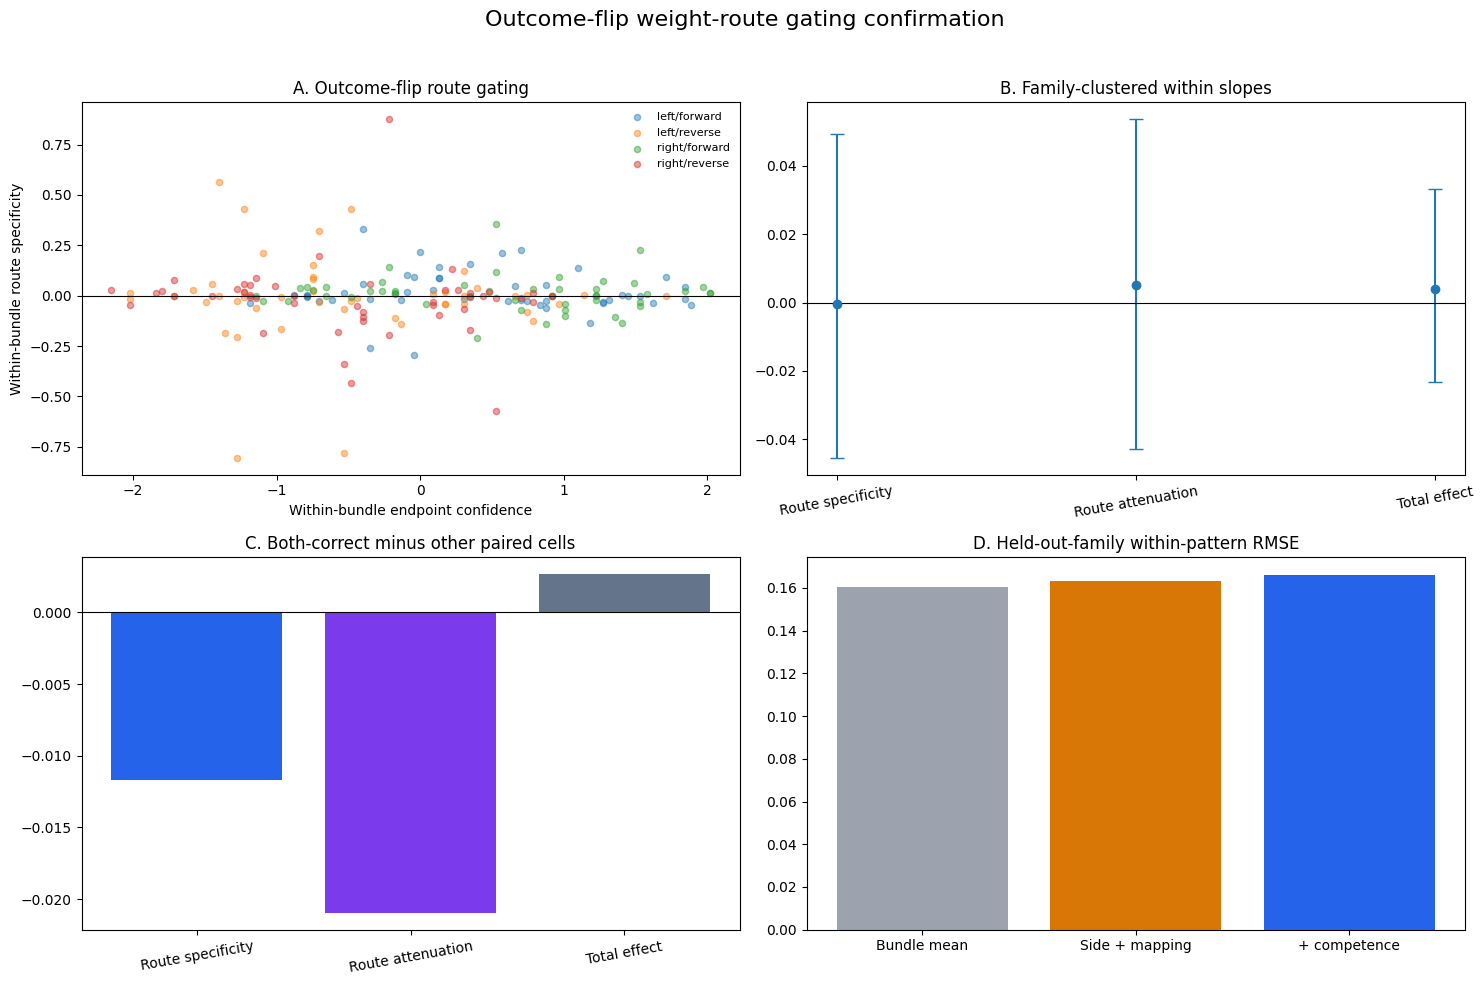

# Outcome-Flip Within-Context Route-Gating Confirmation

**Primary decision:** outcomeflip_route_gating_not_confirmed

- Families / bundles / cells: 43 / 48 / 192
- Within route-specificity slope: -0.00032 [-0.04544, 0.04925]
- Within route-attenuation slope: 0.00502 [-0.04302, 0.05364]
- Boundary total-effect slope: 0.00403 [-0.02333, 0.03315]
- Matched correctness difference: -0.01167 [-0.04168, 0.02037]
- Held-out MSE gain: -0.00125 [-0.00282, 0.00016]
- Route-blocking advantage: 0.00521 [-0.01064, 0.02273]

## Gates

- adequate_bundle_support: True
- adequate_family_support: True
- adequate_discordant_support: True
- within_route_specificity_slope_positive: False
- within_route_attenuation_slope_positive: False
- matched_correctness_difference_positive: False
- heldout_prediction_gain_positive: False
- route_blocking_advantage_positive: False

## Claim boundary

This confirmation concerns only controlled visual torque scenes where the weight edit changes the correct outcome. A posi

In [20]:
%%cell_progress 18/18 Save the confirmatory decision, figure, and report
cell_stage('Applying frozen gates and writing paper-facing outputs')

def lookup(metric, term=PRIMARY_COMPETENCE):
    return coefficient_frame[
        (coefficient_frame['metric'] == metric)
        & (coefficient_frame['term'] == term)
    ].iloc[0]

primary = lookup(PRIMARY_METRIC)
confirmatory = lookup(CONFIRMATORY_METRIC)
boundary = lookup(BOUNDARY_METRIC)
matched_primary = matched_tests[matched_tests['metric'] == PRIMARY_METRIC].iloc[0]
gain_primary = gain_frame[gain_frame['metric'] == PRIMARY_METRIC].iloc[0]
transition_primary = transition_tests[
    transition_tests['metric'] == 'route_blocking_advantage'
].iloc[0]
gates = {
    'adequate_bundle_support': bool(EXPECTED_BUNDLES >= MINIMUM_BUNDLES),
    'adequate_family_support': bool(EXPECTED_FAMILIES >= MINIMUM_FAMILIES),
    'adequate_discordant_support': bool(len(matched_frame) >= MINIMUM_DISCORDANT_BUNDLES),
    'within_route_specificity_slope_positive': bool(primary['ci_low'] > 0),
    'within_route_attenuation_slope_positive': bool(confirmatory['ci_low'] > 0),
    'matched_correctness_difference_positive': bool(matched_primary['ci_low'] > 0),
    'heldout_prediction_gain_positive': bool(gain_primary['ci_low'] > 0),
    'route_blocking_advantage_positive': bool(transition_primary['ci_low'] > 0),
}
data_gates = all(gates[key] for key in (
    'adequate_bundle_support', 'adequate_family_support',
    'adequate_discordant_support',
))
if (
    data_gates and gates['within_route_specificity_slope_positive']
    and gates['heldout_prediction_gain_positive']
    and (gates['within_route_attenuation_slope_positive']
         or gates['matched_correctness_difference_positive'])
):
    PRIMARY_DECISION = 'outcomeflip_withincontext_route_gating_confirmed'
elif data_gates and (
    gates['within_route_specificity_slope_positive']
    or gates['matched_correctness_difference_positive']
    or gates['route_blocking_advantage_positive']
):
    PRIMARY_DECISION = 'outcomeflip_route_gating_partially_supported'
else:
    PRIMARY_DECISION = 'outcomeflip_route_gating_not_confirmed'

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for (side, mapping), current in frame.groupby(['changed_side', 'mapping_variant']):
    axes[0, 0].scatter(
        current[PRIMARY_COMPETENCE], current[PRIMARY_METRIC + '_within'],
        s=20, alpha=0.45, label=f'{side}/{mapping}',
    )
axes[0, 0].axhline(0, color='black', linewidth=0.8)
axes[0, 0].set_xlabel('Within-bundle endpoint confidence')
axes[0, 0].set_ylabel('Within-bundle route specificity')
axes[0, 0].set_title('A. Outcome-flip route gating')
axes[0, 0].legend(frameon=False, fontsize=8)

rows = [primary, confirmatory, boundary]
labels = ['Route specificity', 'Route attenuation', 'Total effect']
x = np.arange(3); y = np.asarray([row['estimate'] for row in rows])
yerr = np.vstack([
    y - np.asarray([row['ci_low'] for row in rows]),
    np.asarray([row['ci_high'] for row in rows]) - y,
])
axes[0, 1].errorbar(x, y, yerr=yerr, fmt='o', capsize=5)
axes[0, 1].axhline(0, color='black', linewidth=0.8)
axes[0, 1].set_xticks(x, labels, rotation=10)
axes[0, 1].set_title('B. Family-clustered within slopes')

axes[1, 0].bar(
    np.arange(len(matched_tests)), matched_tests['estimate'],
    color=['#2563EB', '#7C3AED', '#64748B'],
)
axes[1, 0].axhline(0, color='black', linewidth=0.8)
axes[1, 0].set_xticks(np.arange(3), labels, rotation=10)
axes[1, 0].set_title('C. Both-correct minus other paired cells')

primary_comparison = comparison_frame[
    comparison_frame['metric'] == PRIMARY_METRIC
].set_index('model').loc[['bundle_mean', 'factorial', 'within_competence']]
axes[1, 1].bar(
    np.arange(3), primary_comparison['rmse'],
    color=['#9CA3AF', '#D97706', '#2563EB'],
)
axes[1, 1].set_xticks(
    np.arange(3), ['Bundle mean', 'Side + mapping', '+ competence']
)
axes[1, 1].set_title('D. Held-out-family within-pattern RMSE')
fig.suptitle('Outcome-flip weight-route gating confirmation', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
figure_path = FIGURE_DIR / 'outcomeflip_route_gating_confirmation.png'
fig.savefig(figure_path, dpi=220, bbox_inches='tight')

pdf_figure_path = figure_path.with_suffix('.pdf')
try:
    fig.savefig(pdf_figure_path, bbox_inches='tight')
    PDF_FIGURE_SAVED = True
except (ImportError, AttributeError) as error:
    PDF_FIGURE_SAVED = False
    print(f'PDF export skipped: {error}')

plt.show()

decision = {
    'schema_version': 'outcomeflip-route-gating-decision-1.0',
    'primary_decision': PRIMARY_DECISION, 'gates': gates,
    'primary_slope': primary.to_dict(),
    'confirmatory_slope': confirmatory.to_dict(),
    'boundary_slope': boundary.to_dict(),
    'matched_primary': matched_primary.to_dict(),
    'heldout_gain': gain_primary.to_dict(),
    'route_blocking': transition_primary.to_dict(),
    'claim_boundary': (
        'This confirmation concerns only controlled visual torque scenes where '
        'the weight edit changes the correct outcome. A positive association '
        'does not make confidence causal; held-out prediction is required for '
        'the strongest gating claim.'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'confirmatory_decision.json', decision)

def interval(row):
    return f"{row['estimate']:.5f} [{row['ci_low']:.5f}, {row['ci_high']:.5f}]"
lines = [
    '# Outcome-Flip Within-Context Route-Gating Confirmation', '',
    f'**Primary decision:** {PRIMARY_DECISION}', '',
    f'- Families / bundles / cells: {EXPECTED_FAMILIES} / {EXPECTED_BUNDLES} / {len(frame)}',
    f'- Within route-specificity slope: {interval(primary)}',
    f'- Within route-attenuation slope: {interval(confirmatory)}',
    f'- Boundary total-effect slope: {interval(boundary)}',
    f'- Matched correctness difference: {interval(matched_primary)}',
    (
        '- Held-out MSE gain: '
        f"{gain_primary['mse_reduction']:.5f} "
        f"[{gain_primary['ci_low']:.5f}, {gain_primary['ci_high']:.5f}]"
    ),
    f'- Route-blocking advantage: {interval(transition_primary)}', '',
    '## Gates', '',
]
for name, passed in gates.items(): lines.append(f'- {name}: {passed}')
lines.extend(['', '## Claim boundary', '', decision['claim_boundary']])
report_path = ANALYSIS_DIR / 'OUTCOMEFLIP_CONFIRMATORY_REPORT.md'
report_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

write_json_atomic(SHARED_ROOT / 'RUN_COMPLETE.json', {
    'schema_version': 'outcomeflip-route-confirmation-complete-1.0',
    'primary_decision': PRIMARY_DECISION,
    'protocol_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'confirmation_manifest_sha256': sha256_file(CONFIRMATION_MANIFEST_PATH),
    'families': EXPECTED_FAMILIES, 'bundles': EXPECTED_BUNDLES,
    'records': len(record_frame), 'report': str(report_path),
    'figure': str(figure_path),
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
})
print(report_path.read_text(encoding='utf-8'))
print('Run complete:', SHARED_ROOT / 'RUN_COMPLETE.json')
